# Trade Cost and Utility

So far, the numbers of satellites and planes have stood in for cost. This notebook estimates the life-cycle cost of each design, and trades it against what the design achieves.

It covers:

* **costs**, from a cost model and the schedule of each design's deployment;
* **uncertain cost growth**, and the cost at a confidence level as an objective, within a **budget**;
* **utility**, which weighs several objectives by a stakeholder's preferences.

It builds on `ExplainTradeSpace`, whose study measures both shares of points sampled.

## Estimate Costs

Three parts describe the mission of each design (with illustrative costs, in millions of dollars):

* A `DeploymentSchedule`: three years of development; production on one line, at four satellites a year; launches of up to three satellites, at most one every half year; and five years of operations from the first launch.
* A `CostModel`: the costs of developing a satellite of each imager and of producing its first unit (later units cost less, on a learning curve), a cost per launch, and the costs of operations. TAT-C has no cost-estimating relationships: the study gives these costs.
* A `MissionPlan` combines them. It plans each design's deployment by the schedule, and estimates its cost for the satellites of its imager (`kind="field_of_regard"`).

The growth of the cost of development is uncertain: an `Uncertain` parameter (`cost_growth`) from 0.9 to 1.6 times the estimate, most likely 1, drawn for each replicate. `space.extend` adds it to the design space, and the plan multiplies the costs of development by it (`growth`).

In [1]:
from trade_space_example import accuracy_study, describe, planes_name, space
from tatc.tradespace import (
    CostModel,
    DeploymentSchedule,
    LaunchCost,
    MissionPlan,
    OperationsCost,
    SatelliteCost,
    Uncertain,
)

SCHEDULE = DeploymentSchedule(years=5, development_years=3, production_rate=4, launch_interval=0.5, launch_capacity=3)
COST_MODEL = CostModel(
    satellites={  # by field of regard
        30: SatelliteCost(development=40, first_unit=12, learning_rate=0.9, mass=60),
        60: SatelliteCost(development=60, first_unit=18, learning_rate=0.9, mass=90),
    },
    launch=LaunchCost(per_launch=8),
    operations=OperationsCost(per_year=3, per_satellite_year=0.5),
    discount_rate=0.03,
)
PLAN = MissionPlan(SCHEDULE, COST_MODEL, kind="field_of_regard", growth={"development": "cost_growth"})
cost_space = space.extend(cost_growth=Uncertain(lambda rng: float(rng.triangular(0.9, 1.0, 1.6))))
cost_study = accuracy_study.replace(space=cost_space, plan=PLAN)
results = cost_study.run()  # every design of the design space
COSTS = ["cost", "cost development", "cost production", "cost launch", "cost operations"]
results[["satellites", "planes", "field_of_regard", "cost_growth", "deployed", *COSTS]].head().round(2)

,satellites,planes,field_of_regard,cost_growth,deployed,cost,cost development,cost production,cost launch,cost operations
0,1,1,30,1.05,3.25,79.65,42.15,12.0,8.0,17.5
1,1,1,30,1.08,3.25,80.82,43.32,12.0,8.0,17.5
2,1,1,30,1.24,3.25,86.93,49.43,12.0,8.0,17.5
3,1,1,30,1.01,3.25,77.97,40.47,12.0,8.0,17.5
4,1,1,30,1.17,3.25,84.35,46.85,12.0,8.0,17.5


Each evaluation now has the cost of the design and its parts, and the years from the start of development to the design's last launch (`deployed`).

## Trade Cost against Sufficiency

Budgets are often set at a confidence level: a cost within which a design stays with a probability of 70%, the 0.7 `Quantile` of its cost over the replicates (`cost p70`). The criteria:

* minimize the cost at 70% confidence, and maximize the share of points sufficiently sampled;
* require the cost at 70% confidence to be within a budget of 150 million dollars (a `Requirement`).

`aggregate` gives the statistics of the criteria for each design, and `pareto_front` finds the efficient designs among those that meet the requirement.

520 of 1096 designs cost at most 150 at 70% confidence


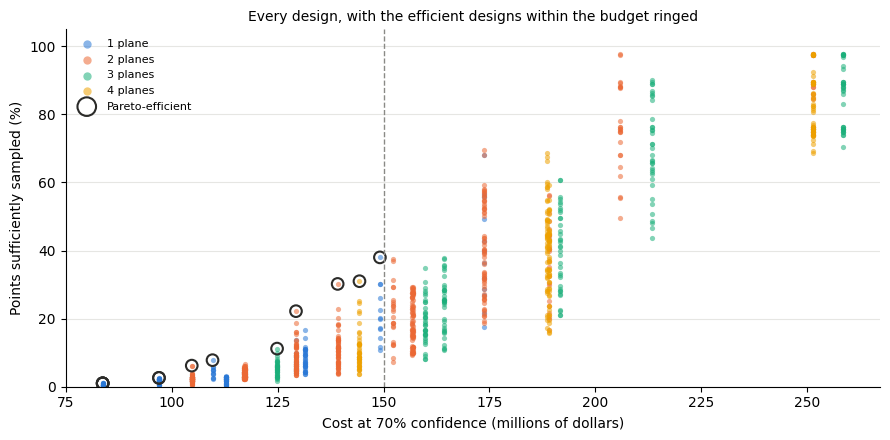

In [2]:
import matplotlib.pyplot as plt

from tatc.tradespace import Criteria, Quantile, Requirement, aggregate, pareto_front, plot_designs
from tatc.tradespace.plotting import GRAY

BUDGET = 150  # millions of dollars, at 70% confidence
COST = Criteria(
    {"cost p70": "min", "sufficient": "max"},
    statistics={"cost p70": Quantile("cost", 0.7)},
    requirements=[Requirement("cost p70", "<=", BUDGET)],
)
costed = aggregate(results, COST)
costed["pareto"] = pareto_front(costed, COST)
print(f"{costed.meets_requirements.sum()} of {len(costed)} designs cost at most {BUDGET} at 70% confidence")

ax = plot_designs(costed, "cost p70", "sufficient", by="planes", front="pareto", names=planes_name, legend="upper left")
ax.axvline(BUDGET, color=GRAY, lw=1, ls="--")
ax.set(xlabel="Cost at 70% confidence (millions of dollars)", ylabel="Points sufficiently sampled (%)", ylim=(0, 105))
ax.set_title("Every design, with the efficient designs within the budget ringed", fontsize=10)
ax.figure.tight_layout()
plt.show()

The efficient designs, with the years until they are deployed and some parts of their costs. A summary keeps the values that are the same in every replicate of a design, such as the cost of launches; the cost of development grows by a different factor in each replicate, so its mean is added:

In [3]:
development = aggregate(results, ["cost development"], design_columns=[]).drop(columns="replicates")
front = costed[costed.pareto].merge(development, on="design").sort_values("cost p70")
front = front.drop_duplicates(["cost p70", "sufficient"])  # one of the designs that tie
front["description"] = front.apply(describe, axis=1)
front[
    ["description", "satellites", "planes", "deployed", "cost development", "cost launch", "cost p70", "sufficient"]
].round(1)

,description,satellites,planes,deployed,cost development,cost launch,cost p70,sufficient
0,"700 km, 30 deg FOR, SSO: 1 at 06:00",1,1,3.2,44.4,8.0,83.6,1.0
7,"800 km, 30 deg FOR, SSO: 2 at 06:00",2,1,3.5,44.4,8.0,96.9,2.6
2,"800 km, 30 deg FOR, Walker 45 deg: 2 x 1 (spac...",2,2,3.8,44.4,16.0,104.7,6.2
1,"800 km, 30 deg FOR, Walker 45 deg: 1 x 3 (spac...",3,1,3.8,44.4,8.0,109.6,7.8
4,"800 km, 30 deg FOR, Walker 45 deg: 3 x 1 (spac...",3,3,4.2,44.4,24.0,124.8,11.2
3,"800 km, 30 deg FOR, Walker 45 deg: 2 x 2 (spac...",4,2,4.0,44.4,16.0,129.3,22.2
12,"800 km, 60 deg FOR, Walker 45 deg: 2 x 1 (spac...",2,2,3.8,66.7,16.0,139.2,30.2
5,"800 km, 30 deg FOR, Walker 45 deg: 4 x 1 (spac...",4,4,4.8,44.4,32.0,144.3,31.0
11,"800 km, 60 deg FOR, Walker 45 deg: 1 x 3 (spac...",3,1,3.8,66.7,8.0,149.1,38.0


520 of the 1,096 designs cost at most 150 million dollars at 70% confidence. Along the front, money buys sufficiency in steps:

* one satellite with the narrower imager costs 84 million dollars, of which 44 million develop it, and samples 1% of the points sufficiently;
* a second satellite costs 97 million in the same plane (3%), and 105 million in a second plane (6%), as each plane needs its own launch;
* four satellites cost 129 million in two planes (22%), and 144 million in four planes (31%): two more launches buy 9 points, as more planes spread the samples in time;
* the wider imager joins the front only near the budget, where its development (67 million against 44) is worth its swath: two satellites with it sample 30% of the points for 139 million, and three of them 38% for 149 million, the most within the budget.

The designs that sample nearly every point (six to nine satellites) cost more than the budget. The deployment of each design follows from its satellites and planes: one satellite is launched 3.2 years after development starts, and four satellites in four planes 4.8 years after, as launches are at least half a year apart. The mean cost of development is the same for every design of an imager, as the growth of each replicate is drawn alike for every design.

## Trade Utility against Cost

Sufficiency and accuracy are separate objectives, each in its own units. A stakeholder who values both must weigh them, and a `Utility` makes the weights explicit:

* a utility of each share, from 0 at its worst value to 1 at its best: linear in the share sufficiently sampled (`LinearUtility`), and concave in the share accurately sampled (`ExponentialUtility`), as the first points accurately sampled matter most;
* weights, which combine the utilities of the shares.

Two stakeholders weigh the shares differently: one mostly sufficiency (0.7 against 0.3), as a center that counts samples for forecasts might, and the other mostly accuracy (0.3 against 0.7), as one that estimates daily means might. A design's utility is that of its mean shares. The figure plots each stakeholder's utility of every design against its cost at 70% confidence, with the front of each stakeholder ringed:

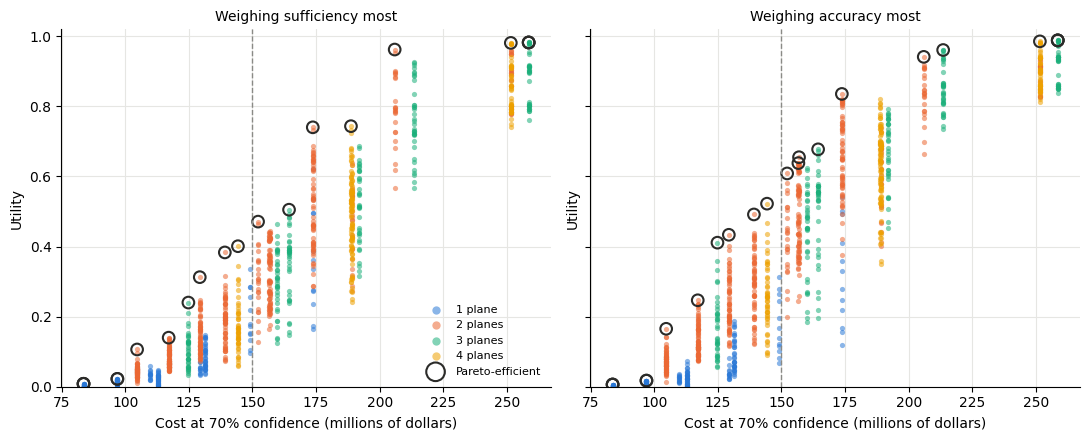

In [4]:
from tatc.tradespace import ExponentialUtility, LinearUtility, Utility, style_axes

CURVES = {"sufficient": LinearUtility(0, 100), "accurate": ExponentialUtility(0, 100, risk=2)}
STAKEHOLDERS = {
    "sufficiency": Utility(CURVES, weights={"sufficient": 0.7, "accurate": 0.3}),
    "accuracy": Utility(CURVES, weights={"sufficient": 0.3, "accurate": 0.7}),
}
means = aggregate(
    results, statistics={"sufficient": "sufficient", "accurate": "accurate", "cost p70": Quantile("cost", 0.7)}
).set_index("design")
means["description"] = means.apply(describe, axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
judged = {}
for ax, (name, utility) in zip(axes, STAKEHOLDERS.items()):
    judged[name] = means.assign(utility=utility(means))
    judged[name]["pareto"] = pareto_front(judged[name], {"utility": "max", "cost p70": "min"})
    legend = "lower right" if ax is axes[0] else None
    plot_designs(
        judged[name], "cost p70", "utility", by="planes", front="pareto", names=planes_name, legend=legend, ax=ax
    )
    ax.axvline(BUDGET, color=GRAY, lw=1, ls="--")
    ax.set(xlabel="Cost at 70% confidence (millions of dollars)", ylabel="Utility", ylim=(0, 1.02))
    ax.set_title(f"Weighing {name} most", fontsize=10)
    style_axes(ax, grid="both")
fig.tight_layout()
plt.show()

The stakeholders' fronts share most of their designs. Those efficient for one stakeholder and not the other:

In [5]:
compared = means[["description", "satellites", "planes", "sufficient", "accurate", "cost p70"]].copy()
for name in STAKEHOLDERS:
    compared[f"utility ({name})"] = judged[name]["utility"]
    compared[f"efficient ({name})"] = judged[name]["pareto"]
print(
    f"{(compared['efficient (sufficiency)'] & compared['efficient (accuracy)']).sum()} designs are efficient for both"
)
compared[compared["efficient (sufficiency)"] != compared["efficient (accuracy)"]].sort_values("cost p70").round(2)

18 designs are efficient for both


,description,satellites,planes,sufficient,accurate,cost p70,utility (sufficiency),efficient (sufficiency),utility (accuracy),efficient (accuracy)
design,,,,,,,,,,
828c0027d01f,"800 km, 60 deg FOR, SSO: 1 at 12:00, 2 at 18:00",3,2,29.2,57.0,156.65,0.44,False,0.64,True
c576e2e2dbd1,"800 km, 60 deg FOR, SSO: 2 at 15:00, 1 at 09:00",3,2,28.8,60.6,156.90,0.45,False,0.66,True
6ba50f2632cd,"800 km, 60 deg FOR, Walker 45 deg: 2 x 2 (spac...",4,2,69.6,65.4,173.73,0.74,True,0.80,False
3690f1194419,"800 km, 60 deg FOR, SSO: 2 at 15:00, 2 at 09:00",4,2,57.6,85.4,173.73,0.69,False,0.84,True
7d5b745cf8f6,"800 km, 60 deg FOR, Walker 45 deg: 4 x 1 (spac...",4,4,68.6,71.2,188.73,0.74,True,0.82,False
64cf6542c326,"800 km, 60 deg FOR, Walker 75 deg: 3 x 2 (spac...",6,3,90.2,95.8,213.53,0.93,False,0.96,True


Within the budget, the stakeholders agree: every design efficient for either of them up to 150 million dollars is efficient for both, as more satellites in more planes buy both shares. Beyond the budget, they part. For 174 million dollars at 70% confidence, the stakeholder of sufficiency prefers four satellites in two Walker planes (70% of the points sufficiently sampled, and 65% accurately), and the stakeholder of accuracy four satellites in two sun-synchronous planes crossing at 09:00 and 15:00 (58% and 85%), whose planes spread the samples over the day. The stakeholder of accuracy also finds three satellites in two sun-synchronous planes efficient for 157 million, and six satellites in three Walker planes for 214 million, which the stakeholder of sufficiency passes over.

## Summary

* A `CostModel` estimates the life-cycle cost of each design from the costs of its satellites, launches, and operations, and a `DeploymentSchedule` dates them by the deployment that it plans from rates of production and launch. A `MissionPlan` combines them in a study.
* Uncertain growth of costs makes the cost at a confidence level (a `Quantile` over the replicates) an objective, and a budget a `Requirement`, in place of the numbers of satellites and planes.
* A `Utility` weighs metrics by a stakeholder's preferences into one objective, to trade against cost.

The next notebook, `PlanDeployment`, accounts for the years over which each design is deployed.

## Notes

* Cost risk has more structure than one factor of growth: the components of satellites grow by their maturity, their growths are correlated, and designs that share components share their growth. `ValidateCostVarianceNSOSA` (in the validation notebooks) models these with `Component`, `Triangular`, and `risk_space`, and compares designs by the probability that one costs more than another (`exceedance`).
* Five replicates make the 0.7 quantile of each design's cost a coarse estimate. An evaluation of the cost alone, which costs little more than the cost model, could draw many more replicates.
* The results also give the present value of each design's cost (`cost present`, discounted at 3% a year) and the cost of its most expensive year (`cost peak annual`), for annual budgets.
* A utility is a metric of any statistic, such as `Quantile(utility, 0.1)`: the utility that a design exceeds in 90% of the replicates. A multiplicative utility (`form="multiplicative"`) makes the shares complements, both of which a design must serve, or substitutes.